# Team 3 — AI Personal Finance and Smart Expense Predictor
## Preprocessing, Validation & Reconciliation notebook (aligned to the generated dataset)

This notebook is matched to the files produced by `generate_dataset.py` (seed 42):
`transactions.csv`, `users.csv`, `monthly_budgets.csv`, `recurring_transactions.csv`, `monthly_financial_summary.csv`, `monthly_expense_forecasting.csv`, `data_dictionary.csv`.

**What it does**
1. Loads the ZIP (or folder) and checks every file's columns against `data_dictionary.csv`.
2. Cleans and validates `transactions.csv` **without altering the dataset's own taxonomy or calendar fields** (categories keep their case; `quarter` stays `Q1..Q4`; `financial_year` stays `FY2022-23`).
3. Treats `payment_status = failed` rows correctly: kept in the clean file, **excluded from every total**.
4. Checks taxonomy, type/category consistency, refund links, recurring-schedule agreement, budgets and user references.
5. Rebuilds the monthly summary with the project's formulas and **reconciles it with `monthly_financial_summary.csv`**.
6. Audits the forecasting table (target construction, leakage, chronological split) and compares baselines with a NumPy least-squares model on a time-aware split.
7. Exports cleaned data, review files, reports and a merged data dictionary.

**Libraries:** pandas (built-in functions such as `read_csv`, `info`, `isna`, `dropna`, `fillna`, `drop_duplicates`, `to_datetime`, `astype`, `quantile`, `groupby`), NumPy, Matplotlib, and scikit-learn preprocessing (`SimpleImputer`, `OneHotEncoder`, `OrdinalEncoder`, `StandardScaler`, `MinMaxScaler`, `RobustScaler`, `ColumnTransformer`, `Pipeline`). Charts are saved to `data/processed/figures/`.

### Preprocessing techniques covered

| No. | Technique | Where in this notebook | What is done here |
|---|---|---|---|
| 1 | Data Collection | Sections 1-2 | `pd.read_csv` for all 7 files from the ZIP/folder |
| 2 | Data Inspection | Section 3 | `shape`, `info`, `dtypes`, `describe`, missing/unique counts, schema check |
| 3 | Missing Value Handling | Section 7 | Documented blanks kept; `dropna(subset=critical)`; `fillna('Unknown')` + indicator for categorical; train-median `SimpleImputer` for numeric features |
| 4 | Duplicate Removal | Section 5 | `duplicated()` / `drop_duplicates()` on full rows and on `transaction_id` |
| 5 | Data Type Conversion | Section 4 | `to_datetime`, `to_numeric`, `astype('string')` |
| 6 | Data Validation | Section 6 | 13 rule checks (amount > 0, taxonomy, dates, refund links, calendar fields...) |
| 7 | Outlier Detection | Section 11 | Per-subcategory IQR fences and modified z-score on log-amount; flagged, never silently removed |
| 8 | Data Standardization | Section 4 | Trimmed text, common date format `YYYY-MM-DD`, consistent type/status/currency spelling |
| 9 | Categorical Encoding | Section 13 | `OneHotEncoder` (nominal) and `OrdinalEncoder` (ordered: weekday, quarter) |
| 10 | Feature Engineering | Section 12 | day, ISO week, month start/end, hour, `log_amount`, days since previous transaction, missing indicators |
| 11 | Data Scaling | Section 14 | `StandardScaler` (plus `MinMaxScaler` / `RobustScaler` comparison), fitted on training rows only |
| 12 | Data Splitting | Section 15 | Chronological train 2022-23 / validation 2024 / test 2025 (no shuffling) |
| 13 | Documentation | Sections 16-18 | Data dictionary, feature definitions, JSON validation report, saved pipeline |

**Rules:** nothing is imputed or silently dropped; rejected rows go to a review file. Blank cells that the generator leaves on purpose (e.g. unknown merchant for cash payments) are reported as *documented*, not as errors.

## 1. Imports and configuration  *(Technique 1: Data Collection - setup)*

In [21]:
from pathlib import Path
from zipfile import ZipFile
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 100)

START_DATE = pd.Timestamp("2022-01-01")
END_DATE = pd.Timestamp("2025-12-31")

# Set INPUT_PATH yourself if needed (a folder containing the CSVs, or the ZIP file).
CANDIDATES = [Path("ai_personal_finance_dataset.zip"), Path("data/raw"), Path(".")]
INPUT_PATH = next(
    (p for p in CANDIDATES if p.exists() and (p.is_file() or (p / "transactions.csv").exists())), None
)
if INPUT_PATH is None:
    raise FileNotFoundError("Put ai_personal_finance_dataset.zip (or the CSVs) next to this notebook, or set INPUT_PATH.")

OUTPUT_DIR = Path("data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
print("Input :", INPUT_PATH.resolve())
print("Output:", OUTPUT_DIR.resolve())

Input : C:\Users\mitul jain\Downloads\AI_Personel_finance\ai_personal_finance_dataset.zip
Output: C:\Users\mitul jain\Downloads\AI_Personel_finance\data\processed


## 2. Locate and load the dataset files  *(Technique 1: Data Collection)*

In [22]:
EXPECTED_FILES = ["transactions", "users", "monthly_budgets", "recurring_transactions",
                  "monthly_financial_summary", "monthly_expense_forecasting", "data_dictionary"]

if INPUT_PATH.is_file() and INPUT_PATH.suffix.lower() == ".zip":
    extract_dir = Path("data/extracted")
    extract_dir.mkdir(parents=True, exist_ok=True)
    with ZipFile(INPUT_PATH) as zf:
        zf.extractall(extract_dir)
    search_root = extract_dir
else:
    search_root = INPUT_PATH

tx_files = list(search_root.rglob("transactions.csv"))
if not tx_files:
    raise FileNotFoundError(f"transactions.csv not found under {search_root.resolve()}")
DATA_ROOT = tx_files[0].parent

datasets = {}
for name in EXPECTED_FILES:
    path = DATA_ROOT / f"{name}.csv"
    if path.exists():
        datasets[name] = pd.read_csv(path, low_memory=False)
        print(f"Loaded {path.name:36s} {datasets[name].shape[0]:>8,} rows x {datasets[name].shape[1]:>3} cols")
    else:
        print(f"MISSING {path.name} (related checks will be skipped)")
assert "transactions" in datasets, "transactions.csv is required"

Loaded transactions.csv                       67,945 rows x  32 cols
Loaded users.csv                                 150 rows x  13 cols
Loaded monthly_budgets.csv                    66,672 rows x  10 cols
Loaded recurring_transactions.csv              3,208 rows x  12 cols
Loaded monthly_financial_summary.csv           7,200 rows x  21 cols
Loaded monthly_expense_forecasting.csv         7,050 rows x  65 cols
Loaded data_dictionary.csv                       153 rows x   5 cols


## 3. Data inspection: profiling and schema check  *(Technique 2)*

In [3]:
profile = pd.DataFrame([{
    "dataset": n, "rows": len(df), "columns": df.shape[1],
    "duplicate_rows": int(df.duplicated().sum()),
    "columns_with_missing": int(df.isna().any().sum()),
    "missing_cells": int(df.isna().sum().sum()),
} for n, df in datasets.items()])
display(profile)

schema_rows = []
if "data_dictionary" in datasets:
    dd = datasets["data_dictionary"]
    for fname, grp in dd.groupby("file"):
        key = fname.replace(".csv", "")
        if key in datasets:
            expected, actual = list(grp["column"]), list(datasets[key].columns)
            schema_rows.append({
                "file": fname,
                "missing_columns": [c for c in expected if c not in actual],
                "unexpected_columns": [c for c in actual if c not in expected],
                "column_order_matches": expected == actual,
            })
schema_report = pd.DataFrame(schema_rows)
display(schema_report)

,dataset,rows,columns,duplicate_rows,columns_with_missing,missing_cells
0,transactions,67945,32,0,5,125147
1,users,150,13,0,0,0
2,monthly_budgets,66672,10,0,0,0
3,recurring_transactions,3208,12,0,1,1175
4,monthly_financial_summary,7200,21,0,1,68
5,monthly_expense_forecasting,7050,65,0,5,2700
6,data_dictionary,153,5,0,0,0


,file,missing_columns,unexpected_columns,column_order_matches
0,monthly_budgets.csv,[],[],True
1,monthly_expense_forecasting.csv,[],[],True
2,monthly_financial_summary.csv,[],[],False
3,recurring_transactions.csv,[],[],True
4,transactions.csv,[],[],True
5,users.csv,[],[],True


## 4. Type conversion and standardization of `transactions.csv`  *(Techniques 5 and 8)*
Only light, non-destructive standardization: trim text, parse dates, numeric amounts, normalize `transaction_type`/`payment_status` spelling.
**Categories are NOT lower-cased** — the generator's taxonomy is case-sensitive (e.g. `Gifts & Donations`) and later checks depend on it.

In [23]:
def normalize_column_name(c):
    return re.sub(r"[^a-z0-9]+", "_", str(c).strip().lower()).strip("_")

tx_raw = datasets["transactions"].copy()
tx = tx_raw.copy()
tx.columns = [normalize_column_name(c) for c in tx.columns]

for col in tx.select_dtypes(include=["object", "string"]).columns:
    tx[col] = tx[col].astype("string").str.strip().replace({"": pd.NA})

tx["category"] = tx["category"].str.replace(r"\s+", " ", regex=True)
tx["transaction_type"] = tx["transaction_type"].str.lower()
type_map = {"spending": "expense", "debit": "expense", "salary": "income", "credit": "income",
            "reimbursement": "refund", "internal_transfer": "transfer"}
tx["transaction_type"] = tx["transaction_type"].map(lambda x: type_map.get(x, x) if pd.notna(x) else x)
tx["payment_status"] = tx["payment_status"].str.lower()
tx["currency"] = tx["currency"].str.upper()

tx["transaction_date"] = pd.to_datetime(tx["transaction_date"], errors="coerce")
tx["amount"] = pd.to_numeric(tx["amount"], errors="coerce")
print("Shape:", tx.shape)
display(tx.head(3))

Shape: (67945, 32)


,transaction_id,user_id,transaction_date,transaction_time,transaction_type,amount,currency,category,subcategory,description,payment_method,merchant_name,merchant_category,account_type,is_recurring,recurring_frequency,is_essential,planned_or_unplanned,payment_status,transaction_channel,city,state,financial_year,month,month_name,quarter,day_of_week,weekend_flag,needs_or_wants,data_source,recurring_id,related_transaction_id
0,TXN0000001,U0048,2022-01-01,01:24:16,transfer,1000.0,INR,Savings and Investments,recurring_deposit,Recurring deposit instalment,Auto Debit,Unity Bank Recurring Deposit,Bank Deposit,savings_account,1,monthly,0,not_applicable,completed,auto_debit,Pune,Maharashtra,FY2021-22,1,January,Q1,Saturday,1,savings,bank_statement_import,REC0048_16,<NA>
1,TXN0000002,U0150,2022-01-01,01:30:44,expense,118.0,INR,Financial Expenses,bank_fees,Bank service charges,Auto Debit,Civic Bank Charges,Bank,savings_account,0,<NA>,1,planned,completed,auto_debit,Surat,Gujarat,FY2021-22,1,January,Q1,Saturday,1,needs,bank_statement_import,<NA>,<NA>
2,TXN0000003,U0101,2022-01-01,02:05:09,transfer,4000.0,INR,Savings and Investments,sip_mutual_fund,Mutual fund SIP contribution,Net Banking,Pinnacle Asset Management,Mutual Fund,savings_account,1,monthly,0,not_applicable,completed,bank_portal,Mumbai,Maharashtra,FY2021-22,1,January,Q1,Saturday,1,savings,bank_statement_import,REC0101_14,<NA>


## 5. Duplicate removal  *(Technique 4)*
Exact duplicate rows are removed (the generator already removes them, so 0 is expected). A repeated `transaction_id` with different content is written to a review file.

In [24]:
exact_duplicate_count = int(tx.duplicated().sum())
tx = tx.drop_duplicates().copy()

dup_mask = tx["transaction_id"].duplicated(keep=False)
duplicate_id_records = tx[dup_mask].sort_values("transaction_id")
duplicate_id_rows_removed = int(tx["transaction_id"].duplicated(keep="first").sum())
tx = tx.drop_duplicates(subset=["transaction_id"], keep="first").copy()

duplicate_id_records.to_csv(OUTPUT_DIR / "duplicate_transaction_ids_for_review.csv", index=False)
print(f"Exact duplicate rows removed : {exact_duplicate_count}")
print(f"Duplicate-ID rows removed    : {duplicate_id_rows_removed}")

Exact duplicate rows removed : 0
Duplicate-ID rows removed    : 0


## 6. Data validation  *(Technique 6)*
Checks (each becomes a `validation_*` flag; rows with any flag go to the review file):
core fields, dates and period, amounts, type, **taxonomy pairs**, **type↔category consistency**, currency, payment status, **derived calendar fields agree with the date**, UPI limit, **refund links**.

In [25]:
EXPENSE_CATEGORIES = ["Housing", "Food", "Transportation", "Utilities", "Healthcare", "Education", "Shopping",
                      "Entertainment", "Personal Care", "Travel", "Gifts & Donations", "Financial Expenses"]
TAXONOMY = {
    "Housing": ["rent", "maintenance", "home_repairs"],
    "Food": ["groceries", "restaurants", "food_delivery"],
    "Transportation": ["public_transport", "fuel", "taxi", "vehicle_maintenance", "vehicle_insurance"],
    "Utilities": ["electricity", "water", "gas", "internet", "mobile_recharge"],
    "Healthcare": ["consultation", "medicine", "diagnostic_tests", "insurance"],
    "Education": ["tuition", "books", "online_courses"],
    "Shopping": ["clothing", "electronics", "household_goods"],
    "Entertainment": ["movies", "subscriptions", "events"],
    "Personal Care": ["grooming", "toiletries"],
    "Travel": ["train_bus_ticket", "flights", "hotel_stay"],
    "Gifts & Donations": ["gifts", "donations"],
    "Financial Expenses": ["bank_fees", "loan_payment", "interest_charges"],
    "Income": ["salary", "freelance_work", "business_income", "incentives", "other_income"],
    "Savings and Investments": ["sip_mutual_fund", "recurring_deposit", "ppf_contribution", "fixed_deposit", "savings_withdrawal"],
    "Transfers": ["own_account_transfer", "atm_cash_withdrawal"],
}
SUB_TO_CAT = {s: c for c, subs in TAXONOMY.items() for s in subs}
VALID_TYPES = {"income", "expense", "refund", "transfer"}

# Refund integrity: each refund must point to a completed expense of the same user and subcategory,
# must not exceed the original amount, and must not precede it.
orig = tx[["transaction_id", "user_id", "transaction_type", "subcategory", "amount", "transaction_date", "payment_status"]].add_suffix("_orig")
ref = tx.loc[tx.transaction_type.eq("refund"),
             ["transaction_id", "user_id", "subcategory", "amount", "transaction_date", "related_transaction_id"]]
m = ref.merge(orig, left_on="related_transaction_id", right_on="transaction_id_orig", how="left")
bad_ref = (m.transaction_id_orig.isna() | m.transaction_type_orig.ne("expense") | m.user_id.ne(m.user_id_orig)
           | m.subcategory.ne(m.subcategory_orig) | m.payment_status_orig.ne("completed")
           | (m.amount > m.amount_orig + 0.005) | (m.transaction_date < m.transaction_date_orig))
bad_refund_ids = set(m.loc[bad_ref, "transaction_id"])

d = tx["transaction_date"]
expected_cat = tx["subcategory"].map(SUB_TO_CAT)
flags = pd.DataFrame(index=tx.index)
flags["validation_missing_id"] = tx["transaction_id"].isna() | tx["user_id"].isna()
flags["validation_bad_date"] = d.isna()
flags["validation_outside_period"] = d.notna() & ~d.between(START_DATE, END_DATE)
flags["validation_bad_amount"] = tx["amount"].isna() | (tx["amount"] <= 0)
flags["validation_bad_type"] = ~tx["transaction_type"].isin(VALID_TYPES)
flags["validation_missing_category"] = tx["category"].isna() | tx["subcategory"].isna()
flags["validation_bad_taxonomy"] = expected_cat.ne(tx["category"]).fillna(True)
flags["validation_type_category_mismatch"] = (
    (tx.transaction_type.isin(["expense", "refund"]) & ~tx.category.isin(EXPENSE_CATEGORIES))
    | (tx.transaction_type.eq("income") & tx.category.ne("Income"))
    | (tx.transaction_type.eq("transfer") & ~tx.category.isin(["Savings and Investments", "Transfers"]))
)
flags["validation_bad_currency"] = tx["currency"].ne("INR")
flags["validation_bad_status"] = ~tx["payment_status"].isin(["completed", "failed"])
flags["validation_calendar_mismatch"] = (
    d.notna() & ((tx["month"] != d.dt.month) | (tx["month_name"] != d.dt.month_name())
                 | (tx["day_of_week"] != d.dt.day_name())
                 | (tx["weekend_flag"].astype("float") != (d.dt.dayofweek >= 5).astype(float)))
)
flags["validation_upi_over_limit"] = tx["payment_method"].eq("UPI") & (tx["amount"] > 100000)
flags["validation_bad_refund_link"] = tx["transaction_id"].isin(bad_refund_ids)
flags = flags.fillna(True).astype(bool)

validation_columns = list(flags.columns)
tx = pd.concat([tx, flags], axis=1)
tx["validation_issue_count"] = flags.sum(axis=1)

invalid_transactions = tx[tx["validation_issue_count"] > 0].copy()
clean_transactions = tx[tx["validation_issue_count"] == 0].drop(columns=validation_columns + ["validation_issue_count"]).copy()
clean_transactions["year"] = clean_transactions["transaction_date"].dt.year.astype("int16")   # only added column; others are kept as generated

# Analysis set: failed payment attempts are retained for audit but never counted in any total.
analysis_tx = clean_transactions[clean_transactions["payment_status"] == "completed"].copy()

display(flags.sum().rename("rows_flagged").to_frame())
print(f"Rows checked: {len(tx):,} | clean: {len(clean_transactions):,} | rejected: {len(invalid_transactions):,}")
print(f"Completed (analysis) rows: {len(analysis_tx):,} | failed attempts kept for audit: {int((clean_transactions.payment_status=='failed').sum()):,}")

out = clean_transactions.copy()
out["transaction_date"] = out["transaction_date"].dt.strftime("%Y-%m-%d")
out.to_csv(OUTPUT_DIR / "transactions_clean.csv", index=False)
inv = invalid_transactions.copy()
inv["transaction_date"] = inv["transaction_date"].dt.strftime("%Y-%m-%d")
inv.to_csv(OUTPUT_DIR / "transactions_rejected_for_review.csv", index=False)

,rows_flagged
validation_missing_id,0
validation_bad_date,0
validation_outside_period,0
validation_bad_amount,0
validation_bad_type,0
validation_missing_category,0
validation_bad_taxonomy,0
validation_type_category_mismatch,0
validation_bad_currency,0
validation_bad_status,0


Rows checked: 67,945 | clean: 67,945 | rejected: 0
Completed (analysis) rows: 67,639 | failed attempts kept for audit: 306


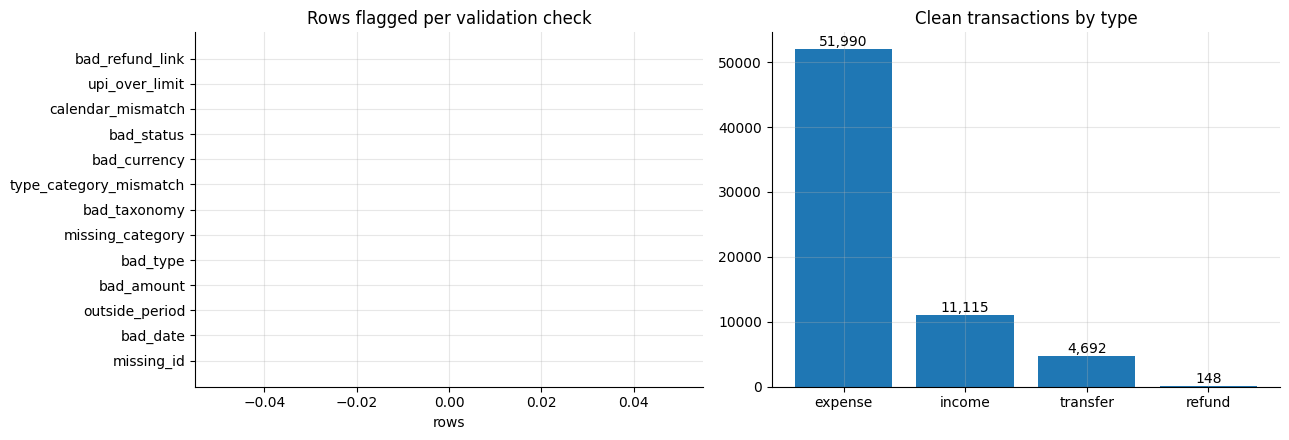

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
counts = flags.sum().sort_values()
ax[0].barh(counts.index.str.replace("validation_", "", regex=False), counts.values)
ax[0].set_title("Rows flagged per validation check"); ax[0].set_xlabel("rows")
tc = clean_transactions.transaction_type.value_counts()
ax[1].bar(tc.index, tc.values); ax[1].set_title("Clean transactions by type")
for i, v in enumerate(tc.values): ax[1].text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_validation_and_types.png", dpi=120); plt.show()

## 7. Missing value handling  *(Technique 3)*
The generator leaves some cells blank **on purpose**. Those are reported as *documented*; any other blank cell is flagged *UNEXPECTED*.

In [26]:
DOCUMENTED_MISSING = {
    "transaction_time": "unknown time-of-day (some manual cash entries)",
    "merchant_name": "unknown merchant (informal cash payments)",
    "recurring_frequency": "not applicable: non-recurring transaction",
    "recurring_id": "not applicable: non-recurring transaction",
    "related_transaction_id": "not applicable: only refunds link to an original expense",
}
mr = pd.DataFrame({
    "missing_count": clean_transactions.isna().sum(),
    "missing_pct": (clean_transactions.isna().mean() * 100).round(2),
})
mr = mr[mr.missing_count > 0].copy()
mr["status"] = [("documented: " + DOCUMENTED_MISSING[c]) if c in DOCUMENTED_MISSING else "UNEXPECTED" for c in mr.index]
display(mr)
assert not mr["status"].eq("UNEXPECTED").any(), "Unexpected missing values found"
mr.to_csv(OUTPUT_DIR / "transaction_missing_value_report.csv")
# Conditional rules: blank recurring fields must coincide with is_recurring == 0.
print("Recurring flag without id/frequency:",
      int(((clean_transactions.is_recurring == 1) & (clean_transactions.recurring_id.isna() | clean_transactions.recurring_frequency.isna())).sum()))

,missing_count,missing_pct,status
transaction_time,1875,2.76,documented: unknown time-of-day (some manual cash entries)
merchant_name,753,1.11,documented: unknown merchant (informal cash payments)
recurring_frequency,27361,40.27,documented: not applicable: non-recurring transaction
recurring_id,27361,40.27,documented: not applicable: non-recurring transaction
related_transaction_id,67797,99.78,documented: not applicable: only refunds link to an original expense


Recurring flag without id/frequency: 0


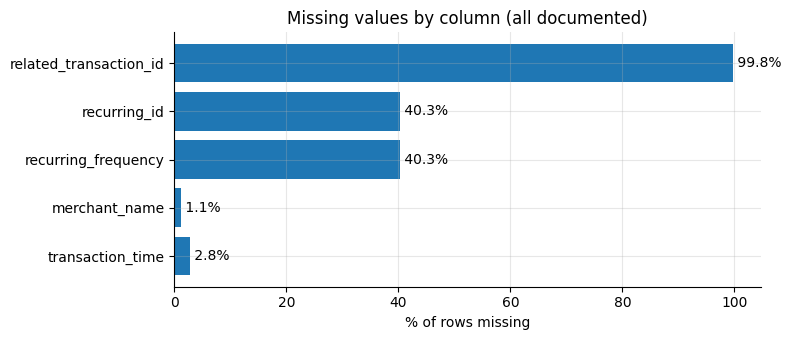

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(mr.index, mr["missing_pct"]); ax.set_xlabel("% of rows missing"); ax.set_title("Missing values by column (all documented)")
for i, v in enumerate(mr["missing_pct"]): ax.text(v, i, f" {v:.1f}%", va="center")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_missing_values.png", dpi=120); plt.show()

In [27]:
# Technique 3 - handling decisions (pandas built-ins)
CRITICAL = ["transaction_id", "user_id", "transaction_date", "transaction_type", "amount", "category"]
n_before = len(clean_transactions)
clean_transactions = clean_transactions.dropna(subset=CRITICAL)        # critical fields are never imputed
analysis_tx = clean_transactions[clean_transactions["payment_status"] == "completed"].copy()
print(f"Rows dropped for missing critical fields: {n_before - len(clean_transactions)} (they would go to the review file)")

# Optional categorical field: keep NA in the cleaned file; in the ML copy use an explicit label + indicator (done in Section 12).
# Numeric ML features with structural gaps (e.g. first-month lags, unknown hour): median imputation fitted on TRAIN rows only (Sections 14-15).
missing_handling = pd.DataFrame([
    ("transaction_time / merchant_name / recurring_* / related_transaction_id", "documented blanks", "kept as NA in transactions_clean.csv"),
    ("merchant_name (ML copy)", "categorical", "fillna('Unknown') + merchant_missing indicator"),
    ("hour, days_since_prev_txn (ML copy)", "numeric", "SimpleImputer(median) fitted on training rows, inside the pipeline"),
    ("exp_lag1..3, exp_target_month_last_year, exp_roll_std_6 (forecast table)", "numeric, early-history gaps", "SimpleImputer(median) fitted on training rows"),
    ("amount, dates, ids, type, category", "critical", "never imputed; dropna(subset=...) -> review file"),
], columns=["field", "kind", "treatment"])
display(missing_handling)
missing_handling.to_csv(OUTPUT_DIR / "missing_value_handling_decisions.csv", index=False)

Rows dropped for missing critical fields: 0 (they would go to the review file)


,field,kind,treatment
0,transaction_time / merchant_name / recurring_* / related_transaction_id,documented blanks,kept as NA in transactions_clean.csv
1,merchant_name (ML copy),categorical,fillna('Unknown') + merchant_missing indicator
2,"hour, days_since_prev_txn (ML copy)",numeric,"SimpleImputer(median) fitted on training rows, inside the pipeline"
3,"exp_lag1..3, exp_target_month_last_year, exp_roll_std_6 (forecast table)","numeric, early-history gaps",SimpleImputer(median) fitted on training rows
4,"amount, dates, ids, type, category",critical,never imputed; dropna(subset=...) -> review file


## 8. Referential integrity: users, budgets, recurring schedules  *(Technique 6, continued)*

In [28]:
ri = []
users = datasets.get("users")
if users is not None:
    known = set(users["user_id"])
    ri.append({"check": "users.user_id unique", "issues": int(users["user_id"].duplicated().sum())})
    ri.append({"check": "transactions -> users", "issues": int((~clean_transactions.user_id.isin(known)).sum())})

budgets = datasets.get("monthly_budgets")
if budgets is not None:
    ri.append({"check": "budgets: unknown user", "issues": int((~budgets.user_id.isin(known)).sum())})
    ri.append({"check": "budgets: duplicate budget_id", "issues": int(budgets.budget_id.duplicated().sum())})
    ri.append({"check": "budgets: duplicate user-year-month-category", "issues": int(budgets.duplicated(["user_id", "year", "month", "category"]).sum())})
    ri.append({"check": "budgets: invalid month/category/amount",
               "issues": int((~budgets.month.between(1, 12) | ~budgets.category.isin(EXPENSE_CATEGORIES) | (budgets.budget_amount <= 0)).sum())})

PERIOD = {"monthly": 1, "bimonthly": 2, "quarterly": 3, "half_yearly": 6, "annual": 12}
rec = datasets.get("recurring_transactions")
if rec is not None:
    rec = rec.copy()
    rec["start_date"] = pd.to_datetime(rec["start_date"])
    rec["end_date"] = pd.to_datetime(rec["end_date"])
    sched = []
    for r in rec.itertuples():
        s = (r.start_date.year - 2022) * 12 + r.start_date.month - 1
        e = 47 if pd.isna(r.end_date) else (r.end_date.year - 2022) * 12 + r.end_date.month - 1
        sched += [(r.recurring_id, t, r.expected_amount, r.subcategory) for t in range(s, e + 1, PERIOD[r.frequency])]
    E = pd.DataFrame(sched, columns=["recurring_id", "t", "expected_amount", "subcategory"])
    A = analysis_tx[analysis_tx.recurring_id.notna()].copy()
    A["t"] = (A.transaction_date.dt.year - 2022) * 12 + A.transaction_date.dt.month - 1
    M = E.merge(A[["recurring_id", "t", "amount"]], on=["recurring_id", "t"], how="outer", indicator=True)
    both = M[M._merge == "both"]
    fixed = ~both.subcategory.isin(["electricity", "water", "gas"])      # utilities vary seasonally by design
    ri.append({"check": "recurring: scheduled occurrence missing", "issues": int((M._merge == "left_only").sum())})
    ri.append({"check": "recurring: transaction not on schedule / duplicated", "issues": int((M._merge == "right_only").sum()) + int(A.duplicated(["recurring_id", "t"]).sum())})
    ri.append({"check": "recurring: fixed amount != expected_amount", "issues": int((np.abs(both[fixed].amount - both[fixed].expected_amount) > 0.01).sum())})
    ri.append({"check": "recurring: unknown recurring_id in transactions", "issues": int((~A.recurring_id.isin(rec.recurring_id)).sum())})

referential_integrity_df = pd.DataFrame(ri)
display(referential_integrity_df)
referential_integrity_df.to_csv(OUTPUT_DIR / "referential_integrity_report.csv", index=False)

,check,issues
0,users.user_id unique,0
1,transactions -> users,0
2,budgets: unknown user,0
3,budgets: duplicate budget_id,0
4,budgets: duplicate user-year-month-category,0
5,budgets: invalid month/category/amount,0
6,recurring: scheduled occurrence missing,0
7,recurring: transaction not on schedule / duplicated,0
8,recurring: fixed amount != expected_amount,0
9,recurring: unknown recurring_id in transactions,0


## 9. Rebuild the monthly summary and reconcile with `monthly_financial_summary.csv`  *(Techniques 6 and 10)*
Project definitions (same as the generator and methodology file):
- Only `completed` rows count; **transfers are neither income nor expense**.
- `net_expenses = total_expenses − refunds_received`; `net_cash_flow = total_income − net_expenses`.
- `savings_amount` = SIP/RD/PPF/FD contributions − redemptions; `savings_rate = savings_amount / total_income` (income > 0).

In [29]:
a = analysis_tx.copy()
a["month"] = a["transaction_date"].dt.month
t = a["transaction_type"]
a["income_amount"] = np.where(t.eq("income"), a.amount, 0.0)
a["expense_amount"] = np.where(t.eq("expense"), a.amount, 0.0)
a["essential_amount"] = np.where(t.eq("expense") & a.is_essential.eq(1), a.amount, 0.0)
a["refund_amount"] = np.where(t.eq("refund"), a.amount, 0.0)
sv = t.eq("transfer") & a.category.eq("Savings and Investments")
a["sav_contrib"] = np.where(sv & a.subcategory.ne("savings_withdrawal"), a.amount, 0.0)
a["sav_redeem"] = np.where(sv & a.subcategory.eq("savings_withdrawal"), a.amount, 0.0)

rebuilt = (a.groupby(["user_id", "year", "month"], as_index=False)
             .agg(total_income=("income_amount", "sum"), total_expenses=("expense_amount", "sum"),
                  essential_expenses=("essential_amount", "sum"), refunds_received=("refund_amount", "sum"),
                  sav_contrib=("sav_contrib", "sum"), sav_redeem=("sav_redeem", "sum"),
                  transaction_count=("transaction_id", "nunique")))
rebuilt["discretionary_expenses"] = rebuilt.total_expenses - rebuilt.essential_expenses
rebuilt["net_expenses"] = rebuilt.total_expenses - rebuilt.refunds_received
rebuilt["net_cash_flow"] = rebuilt.total_income - rebuilt.net_expenses
rebuilt["savings_amount"] = rebuilt.sav_contrib - rebuilt.sav_redeem
rebuilt["savings_rate"] = np.where(rebuilt.total_income > 0, rebuilt.savings_amount / rebuilt.total_income.where(rebuilt.total_income > 0, 1), np.nan)
rebuilt = rebuilt.drop(columns=["sav_contrib", "sav_redeem"])
rebuilt.to_csv(OUTPUT_DIR / "monthly_summary_rebuilt_from_clean_transactions.csv", index=False)

summary_given = datasets.get("monthly_financial_summary")
recon_rows = []
if summary_given is not None:
    J = summary_given.merge(rebuilt, on=["user_id", "year", "month"], how="left", suffixes=("", "_rb"))
    for col in ["total_income", "total_expenses", "essential_expenses", "discretionary_expenses", "refunds_received",
                "net_expenses", "net_cash_flow", "savings_amount", "transaction_count"]:
        rb = J[col + "_rb"].fillna(0.0)      # months with no completed rows rebuild to zero
        diff = (J[col] - rb).abs()
        recon_rows.append({"column": col, "user_months_compared": len(J), "mismatches(>0.011)": int((diff > 0.011).sum()),
                           "max_abs_diff": round(float(diff.max()), 4)})
    sr = J["savings_rate"]
    rb_sr = J["savings_rate_rb"]
    recon_rows.append({"column": "savings_rate", "user_months_compared": len(J),
                       "mismatches(>0.011)": int(((sr - rb_sr).abs() > 0.0011).sum()), "max_abs_diff": round(float((sr - rb_sr).abs().max()), 6)})
reconciliation = pd.DataFrame(recon_rows)
display(reconciliation)
if len(reconciliation):
    assert reconciliation["mismatches(>0.011)"].sum() == 0, "Summary does not reconcile with transactions"
    print("Summary file reconciles with the cleaned transactions.")
reconciliation.to_csv(OUTPUT_DIR / "summary_reconciliation_report.csv", index=False)

annual = rebuilt.groupby("year")[["total_income", "total_expenses", "refunds_received", "net_expenses", "net_cash_flow", "savings_amount"]].sum().round(0)
display(annual)

,column,user_months_compared,mismatches(>0.011),max_abs_diff
0,total_income,7200,0,0.00000
1,total_expenses,7200,0,0.00000
2,essential_expenses,7200,0,0.00000
3,discretionary_expenses,7200,0,0.00000
4,refunds_received,7200,0,0.00000
5,net_expenses,7200,0,0.00000
6,net_cash_flow,7200,0,0.00000
7,savings_amount,7200,0,0.00000
8,transaction_count,7200,0,0.00000
9,savings_rate,7200,0,0.00005


Summary file reconciles with the cleaned transactions.


,total_income,total_expenses,refunds_received,net_expenses,net_cash_flow,savings_amount
year,,,,,,
2022,86439622.0,64984351.0,431541.0,64552810.0,21886812.0,6159000.0
2023,91885406.0,70274397.0,745144.0,69529253.0,22356153.0,6031022.0
2024,97292241.0,77491806.0,649147.0,76842660.0,20449581.0,6493549.0
2025,104446834.0,82133375.0,710290.0,81423085.0,23023749.0,5845320.0


### Visual checks of the cleaned data (Matplotlib)

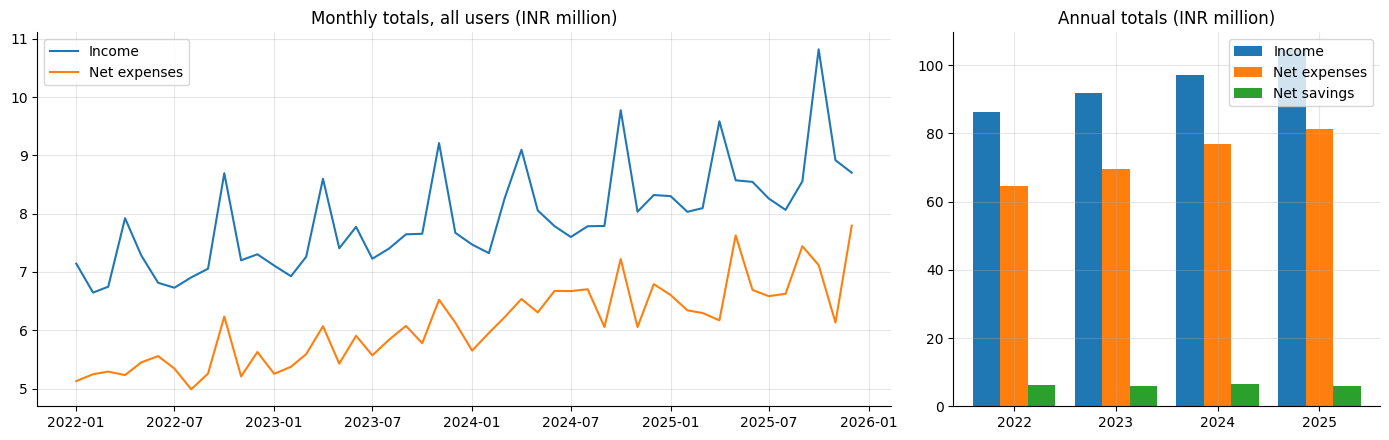

In [13]:
# 1) Monthly income vs net expenses (all users) and annual totals
mt = rebuilt.groupby(["year", "month"])[["total_income", "net_expenses"]].sum().reset_index()
x = pd.to_datetime(dict(year=mt.year, month=mt.month, day=1))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
ax[0].plot(x, mt.total_income / 1e6, label="Income"); ax[0].plot(x, mt.net_expenses / 1e6, label="Net expenses")
ax[0].set_title("Monthly totals, all users (INR million)"); ax[0].legend()
w = 0.27; yrs = annual.index.values; xi = np.arange(len(yrs))
for k, (col, lab) in enumerate([("total_income", "Income"), ("net_expenses", "Net expenses"), ("savings_amount", "Net savings")]):
    ax[1].bar(xi + (k - 1) * w, annual[col] / 1e6, w, label=lab)
ax[1].set_xticks(xi); ax[1].set_xticklabels(yrs); ax[1].set_title("Annual totals (INR million)"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "03_income_vs_expenses.png", dpi=120); plt.show()

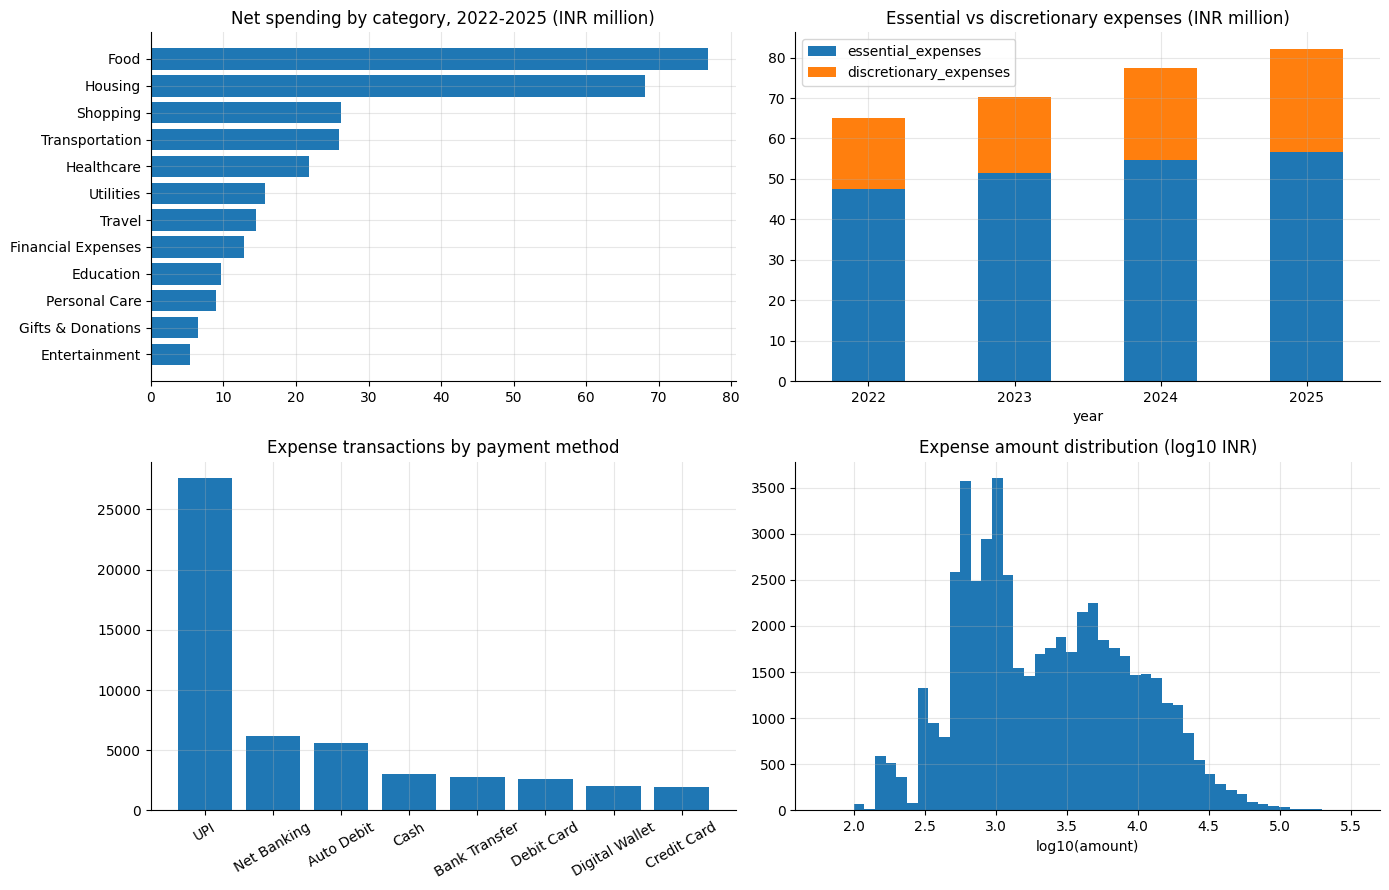

In [30]:
# 2) Category spending, essential vs discretionary by year, payment methods, amount distribution
exp_rows = analysis_tx[analysis_tx.transaction_type == "expense"]
net_cat = (exp_rows.groupby("category").amount.sum()
           .sub(analysis_tx[analysis_tx.transaction_type == "refund"].groupby("category").amount.sum(), fill_value=0)
           .sort_values())
ed = rebuilt.groupby("year")[["essential_expenses", "discretionary_expenses"]].sum() / 1e6
pm = exp_rows.payment_method.value_counts()

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
ax[0, 0].barh(net_cat.index, net_cat.values / 1e6); ax[0, 0].set_title("Net spending by category, 2022-2025 (INR million)")
ed.plot(kind="bar", stacked=True, ax=ax[0, 1], rot=0); ax[0, 1].set_title("Essential vs discretionary expenses (INR million)")
ax[1, 0].bar(pm.index, pm.values); ax[1, 0].set_title("Expense transactions by payment method"); ax[1, 0].tick_params(axis="x", rotation=30)
ax[1, 1].hist(np.log10(exp_rows.amount), bins=50); ax[1, 1].set_title("Expense amount distribution (log10 INR)")
ax[1, 1].set_xlabel("log10(amount)")
plt.tight_layout(); plt.savefig(FIG_DIR / "04_spending_breakdowns.png", dpi=120); plt.show()

/tmp/ipykernel_90/2062646813.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[0].boxplot(bu, labels=order, showfliers=False); ax[0].axhline(100, ls="--", c="grey"); ax[0].set_title("Budget utilization % (capped at 300)")
/tmp/ipykernel_90/2062646813.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[1].boxplot(sr, labels=order, showfliers=False); ax[1].axhline(0, ls="--", c="grey"); ax[1].set_title("Savings rate (clipped to -1..1)")


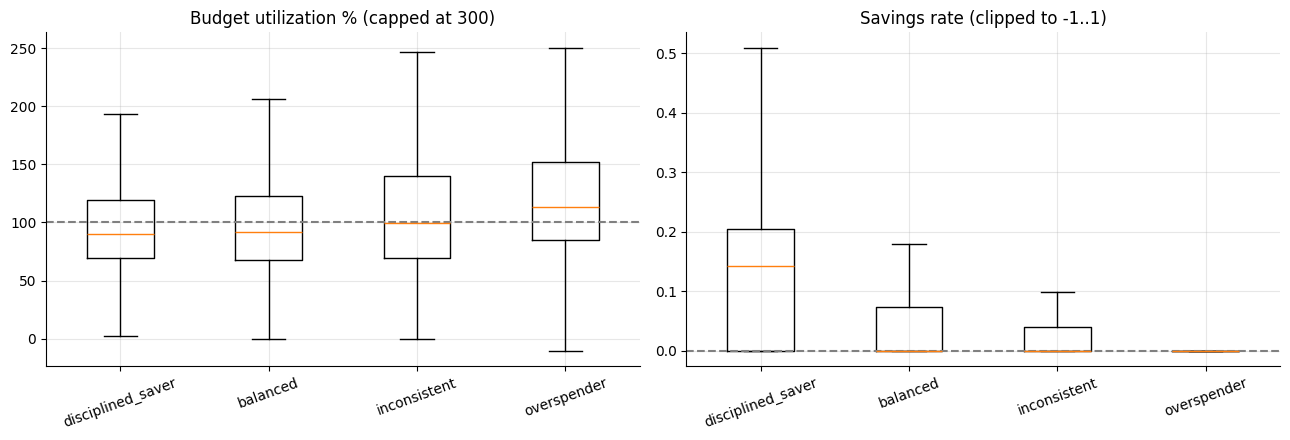

In [15]:
# 3) Budget utilization and savings rate by behaviour archetype
if summary_given is not None and users is not None:
    su = summary_given.merge(users[["user_id", "financial_profile"]], on="user_id")
    order = ["disciplined_saver", "balanced", "inconsistent", "overspender"]
    bu = [su.loc[(su.financial_profile == p) & su.budget_utilization_percentage.notna(), "budget_utilization_percentage"].clip(upper=300).to_numpy() for p in order]
    sr = [su.loc[(su.financial_profile == p) & su.savings_rate.notna(), "savings_rate"].clip(-1, 1).to_numpy() for p in order]
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    ax[0].boxplot(bu, labels=order, showfliers=False); ax[0].axhline(100, ls="--", c="grey"); ax[0].set_title("Budget utilization % (capped at 300)")
    ax[1].boxplot(sr, labels=order, showfliers=False); ax[1].axhline(0, ls="--", c="grey"); ax[1].set_title("Savings rate (clipped to -1..1)")
    for a_ in ax: a_.tick_params(axis="x", rotation=20)
    plt.tight_layout(); plt.savefig(FIG_DIR / "05_profile_behaviour.png", dpi=120); plt.show()

## 10. Audit the forecasting table  *(Techniques 6 and 12)*
Checks that (1) the target equals next month's net expenses from the summary, (2) no forward-looking columns other than the documented target-month calendar/budget/recurring features exist, (3) the split is chronological by *target* month, (the model check on this table is in Section 15).

In [31]:
fc = datasets.get("monthly_expense_forecasting")
if fc is None or summary_given is None:
    print("Forecasting audit skipped (files missing).")
else:
    S = summary_given[["user_id", "year", "month", "net_expenses"]].copy()
    S["t"] = (S.year - 2022) * 12 + S.month - 1
    lookup = S.set_index(["user_id", "t"])["net_expenses"]
    t_fc = (fc.year - 2022) * 12 + fc.month - 1
    nxt = lookup.reindex(pd.MultiIndex.from_arrays([fc.user_id, t_fc + 1])).values
    cur = lookup.reindex(pd.MultiIndex.from_arrays([fc.user_id, t_fc])).values

    allowed_forward = {"target_next_month_expenses", "budget_total_target", "expected_recurring_target"}
    checks = pd.DataFrame([
        {"check": "target != next month's net_expenses", "issues": int((np.abs(nxt - fc.target_next_month_expenses) > 0.011).sum())},
        {"check": "exp_m0 != this month's net_expenses", "issues": int((np.abs(cur - fc.exp_m0) > 0.011).sum())},
        {"check": "unexpected 'next' columns (leakage)", "issues": len([c for c in fc.columns if "next" in c and c not in allowed_forward])},
        {"check": "duplicate user-year-month rows", "issues": int(fc.duplicated(["user_id", "year", "month"]).sum())},
        {"check": "split not chronological by target year",
         "issues": int(not (fc.loc[fc.split == "train", "target_year"].max() < 2024
                            and fc.loc[fc.split == "validation", "target_year"].eq(2024).all()
                            and fc.loc[fc.split == "test", "target_year"].eq(2025).all()))},
    ])
    display(checks)
    assert checks.issues.sum() == 0, "Forecasting table failed an audit check"
    display(fc.split.value_counts().rename("rows").to_frame())

,check,issues
0,target != next month's net_expenses,0
1,exp_m0 != this month's net_expenses,0
2,unexpected 'next' columns (leakage),0
3,duplicate user-year-month rows,0
4,split not chronological by target year,0


,rows
split,
train,3450
validation,1800
test,1800


expenses checked    51684
IQR mild (1.5x)       226
IQR extreme (3x)        0
modified z > 3.5       20
dtype: int64


,outlier_iqr_mild,outlier_iqr_extreme,outlier_modified_z
subcategory,,,
groceries,48,0,1
electricity,30,0,0
vehicle_insurance,28,0,12
restaurants,22,0,1
taxi,14,0,2
gifts,12,0,2
medicine,9,0,0
insurance,8,0,0
food_delivery,8,0,1


C:\Users\mitul jain\AppData\Local\Temp\ipykernel_30984\3406654968.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[0].boxplot([exp.loc[exp.subcategory == c, "log_amount10"] for c in top], labels=top)


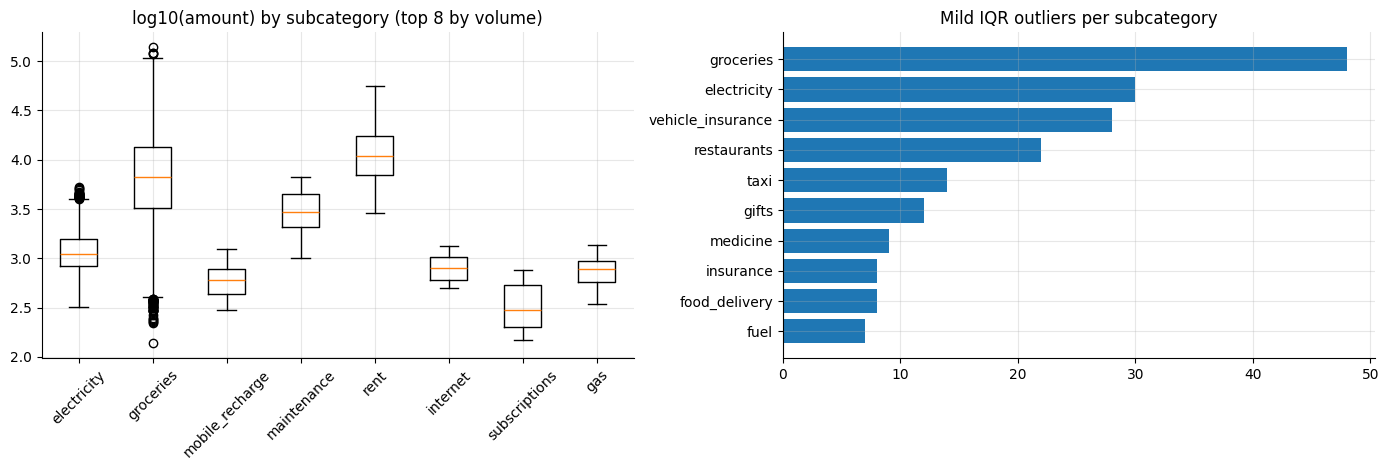

Outliers are flagged for review only: large purchases (e.g. flights, electronics) are legitimate. This is a documented rule-based screen, not a fraud label.


In [32]:
# Technique 7 - outlier detection on log10(amount), per subcategory (flag, do not delete)
exp = analysis_tx[analysis_tx["transaction_type"] == "expense"].copy()
exp["log_amount10"] = np.log10(exp["amount"])
grp = exp.groupby("subcategory")["log_amount10"]
q1 = grp.transform(lambda x: x.quantile(0.25))
q3 = grp.transform(lambda x: x.quantile(0.75))
iqr = q3 - q1
big_enough = grp.transform("size") >= 30
exp["outlier_iqr_mild"] = big_enough & ((exp.log_amount10 > q3 + 1.5 * iqr) | (exp.log_amount10 < q1 - 1.5 * iqr))
exp["outlier_iqr_extreme"] = big_enough & ((exp.log_amount10 > q3 + 3 * iqr) | (exp.log_amount10 < q1 - 3 * iqr))
med = grp.transform("median")
mad = grp.transform(lambda x: (x - x.median()).abs().median())
exp["modified_z"] = 0.6745 * (exp.log_amount10 - med) / mad.replace(0, np.nan)
exp["outlier_modified_z"] = exp["modified_z"].abs() > 3.5

n_extreme = int(exp.outlier_iqr_extreme.sum())
print(pd.Series({"expenses checked": len(exp), "IQR mild (1.5x)": int(exp.outlier_iqr_mild.sum()),
                 "IQR extreme (3x)": n_extreme, "modified z > 3.5": int(exp.outlier_modified_z.sum())}))
by_sub = exp.groupby("subcategory")[["outlier_iqr_mild", "outlier_iqr_extreme", "outlier_modified_z"]].sum().sort_values("outlier_iqr_mild", ascending=False)
display(by_sub.head(10))

review = exp[exp.outlier_iqr_extreme | exp.outlier_modified_z].copy()
review["transaction_date"] = review["transaction_date"].dt.strftime("%Y-%m-%d")
review.to_csv(OUTPUT_DIR / "transactions_outliers_for_review.csv", index=False)

top = exp["subcategory"].value_counts().head(8).index.tolist()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].boxplot([exp.loc[exp.subcategory == c, "log_amount10"] for c in top], labels=top)
ax[0].set_title("log10(amount) by subcategory (top 8 by volume)"); ax[0].tick_params(axis="x", rotation=45)
flag_counts = by_sub["outlier_iqr_mild"].head(10)[::-1]
ax[1].barh(flag_counts.index, flag_counts.values); ax[1].set_title("Mild IQR outliers per subcategory")
plt.tight_layout(); plt.savefig(FIG_DIR / "07_outliers.png", dpi=120); plt.show()
print("Outliers are flagged for review only: large purchases (e.g. flights, electronics) are legitimate. This is a documented rule-based screen, not a fraud label.")

## 12. Feature engineering  *(Technique 10)*
New columns from the cleaned transaction date, time and history. Each feature uses only information available at that transaction (past history only).

In [33]:
ml_tx = (clean_transactions[clean_transactions["payment_status"] == "completed"]
         .sort_values(["user_id", "transaction_date", "transaction_id"]).copy())
d = ml_tx["transaction_date"]
ml_tx["day_of_month"] = d.dt.day
ml_tx["week_of_year"] = d.dt.isocalendar().week.astype(int)
ml_tx["is_month_start"] = d.dt.is_month_start.astype(int)
ml_tx["is_month_end"] = d.dt.is_month_end.astype(int)
ml_tx["hour"] = pd.to_datetime(ml_tx["transaction_time"], format="%H:%M:%S", errors="coerce").dt.hour
ml_tx["log_amount"] = np.log1p(ml_tx["amount"])
ml_tx["days_since_prev_txn"] = ml_tx.groupby("user_id")["transaction_date"].diff().dt.days     # past-only
ml_tx["is_digital"] = (~ml_tx["payment_method"].eq("Cash")).astype(int)
ml_tx["merchant_missing"] = ml_tx["merchant_name"].isna().astype(int)
ml_tx["merchant_name"] = ml_tx["merchant_name"].fillna("Unknown")                              # Technique 3 (categorical)
ml_tx["weekend_flag"] = ml_tx["weekend_flag"].astype(int)
print("ML copy:", ml_tx.shape)
display(ml_tx[["transaction_id", "transaction_date", "amount", "log_amount", "day_of_month", "week_of_year", "hour",
               "days_since_prev_txn", "is_digital", "merchant_missing"]].head())

ML copy: (67639, 42)


,transaction_id,transaction_date,amount,log_amount,day_of_month,week_of_year,hour,days_since_prev_txn,is_digital,merchant_missing
111,TXN0000112,2022-01-02,9200.0,9.127067,2,52,17.0,NaN,1,0
126,TXN0000127,2022-01-02,4350.0,8.378161,2,52,20.0,0.0,1,0
153,TXN0000154,2022-01-03,999.0,6.907755,3,1,11.0,1.0,1,0
213,TXN0000214,2022-01-04,7500.0,8.922792,4,1,4.0,1.0,1,0
492,TXN0000493,2022-01-08,599.0,6.396930,8,1,17.0,4.0,1,0


## 13. Categorical encoding  *(Technique 9)*
Chronological masks are defined first so encoders and scalers are **fitted on training rows only** (Technique 12 is detailed in Section 15).

In [34]:
yr = ml_tx["transaction_date"].dt.year
train_mask, val_mask, test_mask = yr <= 2023, yr == 2024, yr == 2025

NOMINAL = ["payment_method", "transaction_channel", "account_type", "transaction_type", "category", "needs_or_wants", "planned_or_unplanned"]
ORDINAL = {"day_of_week": ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"],
           "quarter": ["Q1", "Q2", "Q3", "Q4"]}

ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
ohe.fit(ml_tx.loc[train_mask, NOMINAL])
oh = pd.DataFrame(ohe.transform(ml_tx[NOMINAL]), columns=ohe.get_feature_names_out(NOMINAL), index=ml_tx.index)

oe = OrdinalEncoder(categories=list(ORDINAL.values()), handle_unknown="use_encoded_value", unknown_value=-1)
oe.fit(ml_tx.loc[train_mask, list(ORDINAL)])
od = pd.DataFrame(oe.transform(ml_tx[list(ORDINAL)]), columns=[c + "_ord" for c in ORDINAL], index=ml_tx.index)

print(f"One-hot columns: {oh.shape[1]} | ordinal columns: {od.shape[1]}")
display(pd.concat([ml_tx[["payment_method", "day_of_week", "quarter"]], oh.filter(like="payment_method_"), od], axis=1).head())

One-hot columns: 46 | ordinal columns: 2


,payment_method,day_of_week,quarter,payment_method_Auto Debit,payment_method_Bank Transfer,payment_method_Cash,payment_method_Credit Card,payment_method_Debit Card,payment_method_Digital Wallet,payment_method_Net Banking,payment_method_UPI,day_of_week_ord,quarter_ord
111,UPI,Sunday,Q1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,6.0,0.0
126,UPI,Sunday,Q1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,6.0,0.0
153,UPI,Monday,Q1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
213,Auto Debit,Tuesday,Q1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
492,Digital Wallet,Saturday,Q1,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,5.0,0.0


## 14. Data scaling  *(Technique 11)*
StandardScaler (mean 0, std 1) is fitted on the training rows only, then applied unchanged to validation and test. MinMaxScaler and RobustScaler are shown for comparison on a skewed feature.

,mean,std
log_amount,0.0,1.0
day_of_month,0.0,1.0
week_of_year,-0.0,1.0
hour,0.0,1.0
days_since_prev_txn,0.0,1.0
is_month_start,-0.0,1.0
is_month_end,0.0,1.0
is_digital,0.0,1.0
weekend_flag,-0.0,1.0
is_recurring,-0.0,1.0


,count,mean,std,min,25%,50%,75%,max
raw,33536.0,3.238,3.442,0.000,1.000,2.000,4.000,28.000
StandardScaler,33536.0,0.000,1.000,-0.941,-0.650,-0.360,0.221,7.195
MinMaxScaler,33536.0,0.116,0.123,0.000,0.036,0.071,0.143,1.000
RobustScaler,33536.0,0.413,1.147,-0.667,-0.333,0.000,0.667,8.667


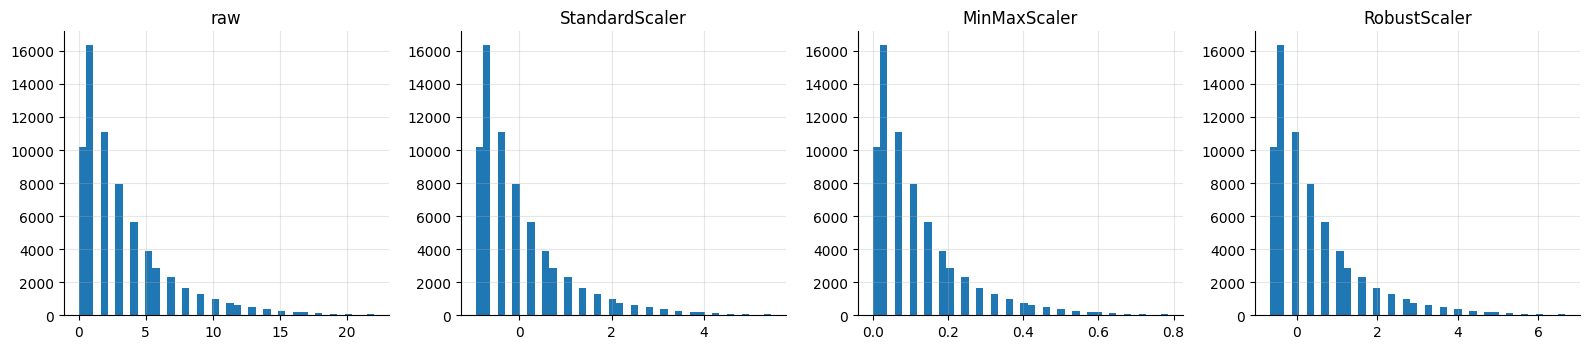

In [35]:
NUMERIC = ["log_amount", "day_of_month", "week_of_year", "hour", "days_since_prev_txn", "is_month_start", "is_month_end",
           "is_digital", "weekend_flag", "is_recurring", "merchant_missing"]

num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
num_pipe.fit(ml_tx.loc[train_mask, NUMERIC])
scaled = pd.DataFrame(num_pipe.transform(ml_tx[NUMERIC]), columns=NUMERIC, index=ml_tx.index)
chk = scaled.loc[train_mask].agg(["mean", "std"]).T.round(3)
display(chk)
assert chk["mean"].abs().max() < 1e-6, "training means should be ~0 after StandardScaler"

# Scaler comparison on a skewed feature (days_since_prev_txn), all fitted on training rows
col = ml_tx[["days_since_prev_txn"]].fillna(ml_tx.loc[train_mask, "days_since_prev_txn"].median())
cmp = pd.DataFrame({
    "raw": col["days_since_prev_txn"],
    "StandardScaler": StandardScaler().fit(col[train_mask]).transform(col).ravel(),
    "MinMaxScaler": MinMaxScaler().fit(col[train_mask]).transform(col).ravel(),
    "RobustScaler": RobustScaler().fit(col[train_mask]).transform(col).ravel(),
}, index=col.index)
display(cmp.loc[train_mask].describe().T.round(3))

fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for a_, c in zip(ax, cmp.columns):
    a_.hist(cmp[c].clip(cmp[c].quantile(0.001), cmp[c].quantile(0.999)), bins=40); a_.set_title(c)
plt.tight_layout(); plt.savefig(FIG_DIR / "08_scaling_comparison.png", dpi=120); plt.show()

## 15. Data splitting and ML-ready outputs  *(Technique 12)*
Chronological split by date (never random): **train 2022-2023, validation 2024, test 2025**. One `ColumnTransformer` (impute + scale numeric, one-hot nominal, ordinal for ordered fields) is fitted on the training rows and applied to every split.

,split,rows,features,first_date,last_date
0,train,33536,59,2022-01-01,2023-12-31
1,validation,17044,59,2024-01-01,2024-12-31
2,test,17059,59,2025-01-01,2025-12-31


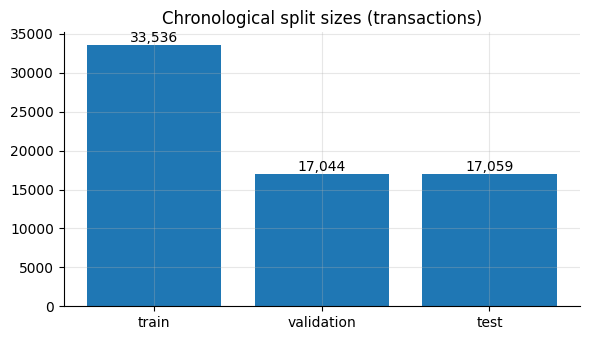

In [36]:
preprocessor_tx = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUMERIC),
    ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False), NOMINAL),
    ("ord", OrdinalEncoder(categories=list(ORDINAL.values()), handle_unknown="use_encoded_value", unknown_value=-1), list(ORDINAL)),
])
preprocessor_tx.fit(ml_tx.loc[train_mask])
feat_names = preprocessor_tx.get_feature_names_out()

splits_tx = {"train": train_mask, "validation": val_mask, "test": test_mask}
dates = ml_tx["transaction_date"]
assert dates[train_mask].max() < dates[val_mask].min() and dates[val_mask].max() < dates[test_mask].min(), "splits overlap in time"
assert (train_mask.astype(int) + val_mask.astype(int) + test_mask.astype(int)).eq(1).all()

sizes = []
for name, mask in splits_tx.items():
    X = pd.DataFrame(preprocessor_tx.transform(ml_tx.loc[mask]), columns=feat_names, index=ml_tx.index[mask])
    X.insert(0, "transaction_id", ml_tx.loc[mask, "transaction_id"].values)
    X.to_csv(OUTPUT_DIR / f"transactions_ml_{name}.csv.gz", index=False, compression="gzip")
    sizes.append({"split": name, "rows": int(mask.sum()), "features": len(feat_names),
                  "first_date": str(dates[mask].min().date()), "last_date": str(dates[mask].max().date())})
split_table = pd.DataFrame(sizes)
display(split_table)
joblib.dump(preprocessor_tx, OUTPUT_DIR / "preprocessor_transactions.joblib")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(split_table.split, split_table.rows); ax.set_title("Chronological split sizes (transactions)")
for i, v in enumerate(split_table.rows): ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout(); plt.savefig(FIG_DIR / "09_split_sizes.png", dpi=120); plt.show()

Forecast features after preprocessing: 64 | rows by split: {'train': 3450, 'validation': 1800, 'test': 1800}
VALIDATION 2024 (fit on 2022-2023 targets)


,model,MAE_INR,RMSE_INR,MAPE_pct(target>=1000),n
0,Baseline: last month,23854.5,42646.5,77.0,1800
1,Baseline: 12-month average,18052.3,32780.2,63.1,1800
2,Baseline: seasonal naive,22441.3,40804.3,71.9,1800
3,LinearRegression,18144.7,33138.5,65.6,1800
4,RandomForest,18083.9,33171.3,67.0,1800


TEST 2025 (fit on 2022-2024 targets)


,model,MAE_INR,RMSE_INR,MAPE_pct(target>=1000),n
0,Baseline: last month,26540.6,48355.7,82.7,1800
1,Baseline: 12-month average,19519.1,35571.9,65.4,1800
2,Baseline: seasonal naive,25144.6,47054.4,77.1,1800
3,LinearRegression,19899.8,35130.8,72.7,1800
4,RandomForest,19532.7,34690.6,71.1,1800


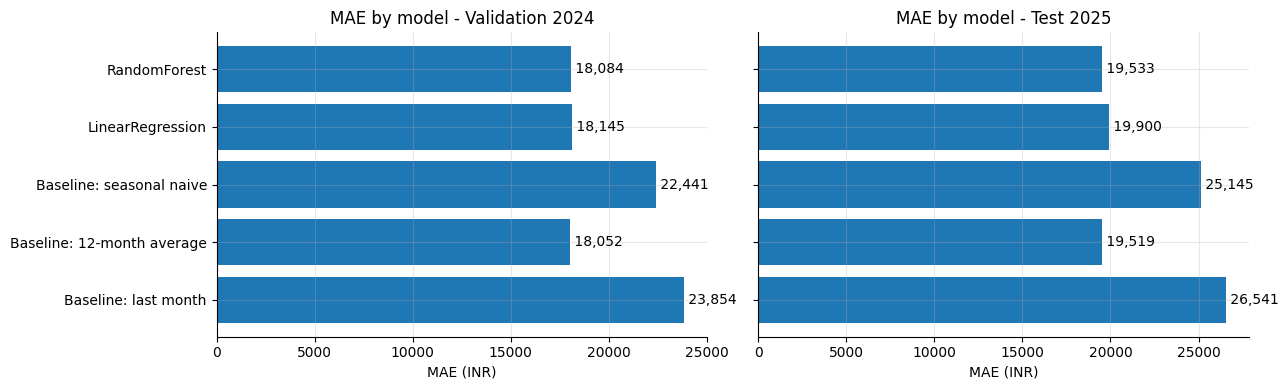

Synthetic-data accuracy does not guarantee real-world accuracy.


In [37]:
# ML-ready forecasting table: same idea at user-month level, fitted on training rows only
assert fc is not None
DROP = ["user_id", "year", "month", "split", "target_year", "target_next_month_expenses"]
FC_CAT = ["employment_type"]
FC_NUM = [c for c in fc.columns if c not in DROP + FC_CAT]
pre_fc = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), FC_NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), FC_CAT),
])
tr = fc.split == "train"
pre_fc.fit(fc.loc[tr, FC_NUM + FC_CAT])
fc_names = pre_fc.get_feature_names_out()
for name in ["train", "validation", "test"]:
    part = fc[fc.split == name]
    Xp = pd.DataFrame(pre_fc.transform(part[FC_NUM + FC_CAT]), columns=fc_names, index=part.index)
    Xp.insert(0, "user_id", part.user_id.values)
    Xp["target_next_month_expenses"] = part.target_next_month_expenses.values
    Xp.to_csv(OUTPUT_DIR / f"forecast_ml_{name}.csv", index=False)
joblib.dump(pre_fc, OUTPUT_DIR / "preprocessor_forecasting.joblib")
print("Forecast features after preprocessing:", len(fc_names), "| rows by split:", fc.split.value_counts().to_dict())

# Sanity model check: pandas baselines vs sklearn pipelines (train 2022-23 -> validate 2024; refit 2022-24 -> test 2025)
def mape(y, p):
    mk = y >= 1000
    return float(np.mean(np.abs(y[mk] - p[mk]) / y[mk]) * 100)

def evaluate(train_splits, eval_split, label):
    trn, tst = fc[fc.split.isin(train_splits)], fc[fc.split == eval_split]
    y = tst.target_next_month_expenses.to_numpy(float)
    rows = []
    for nm, c in [("Baseline: last month", "exp_m0"), ("Baseline: 12-month average", "exp_roll_mean_12"),
                  ("Baseline: seasonal naive", "exp_target_month_last_year")]:
        p = tst[c].to_numpy(float); ok = ~np.isnan(p)
        rows.append((nm, mean_absolute_error(y[ok], p[ok]), np.sqrt(mean_squared_error(y[ok], p[ok])), mape(y[ok], p[ok]), int(ok.sum())))
    for nm, mdl in [("LinearRegression", LinearRegression()),
                    ("RandomForest", RandomForestRegressor(n_estimators=200, max_depth=14, min_samples_leaf=5, n_jobs=-1, random_state=42))]:
        pipe = Pipeline([("prep", ColumnTransformer([
            ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), FC_NUM),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), FC_CAT)])), ("model", mdl)])
        pipe.fit(trn[FC_NUM + FC_CAT], trn.target_next_month_expenses)
        p = np.clip(pipe.predict(tst[FC_NUM + FC_CAT]), 0, None)
        rows.append((nm, mean_absolute_error(y, p), np.sqrt(mean_squared_error(y, p)), mape(y, p), len(y)))
    res = pd.DataFrame(rows, columns=["model", "MAE_INR", "RMSE_INR", "MAPE_pct(target>=1000)", "n"]).round(1)
    print(label); display(res); return res

val_res = evaluate(["train"], "validation", "VALIDATION 2024 (fit on 2022-2023 targets)")
test_res = evaluate(["train", "validation"], "test", "TEST 2025 (fit on 2022-2024 targets)")
val_res.to_csv(OUTPUT_DIR / "forecast_validation_metrics.csv", index=False)
test_res.to_csv(OUTPUT_DIR / "forecast_test_metrics.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a_, res, title in zip(ax, [val_res, test_res], ["Validation 2024", "Test 2025"]):
    a_.barh(res["model"], res["MAE_INR"]); a_.set_title(f"MAE by model - {title}"); a_.set_xlabel("MAE (INR)")
    for i, v in enumerate(res["MAE_INR"]): a_.text(v, i, f" {v:,.0f}", va="center")
plt.tight_layout(); plt.savefig(FIG_DIR / "06_forecast_baselines.png", dpi=120); plt.show()
print("Synthetic-data accuracy does not guarantee real-world accuracy.")

## 16. Data dictionary for the cleaned transactions  *(Technique 13)*

In [38]:
dd_given = datasets.get("data_dictionary")
defs = {}
if dd_given is not None:
    g = dd_given[dd_given.file == "transactions.csv"].set_index("column")
    defs = g["description"].to_dict()
defs["year"] = "Calendar year derived from transaction_date (added by this notebook)."

rows = []
for col in clean_transactions.columns:
    ex = clean_transactions[col].dropna().astype(str).drop_duplicates().head(3).tolist()
    rows.append({"column_name": col, "data_type": str(clean_transactions[col].dtype),
                 "missing_count": int(clean_transactions[col].isna().sum()),
                 "unique_values": int(clean_transactions[col].nunique(dropna=True)),
                 "example_values": " | ".join(ex), "definition": defs.get(col, "Document the business meaning of this field.")})
data_dictionary_clean = pd.DataFrame(rows)
data_dictionary_clean.to_csv(OUTPUT_DIR / "data_dictionary_transactions_clean.csv", index=False)
display(data_dictionary_clean)

,column_name,data_type,missing_count,unique_values,example_values,definition
0,transaction_id,string,0,67945,TXN0000001 | TXN0000002 | TXN0000003,"Unique stable id TXN#######, assigned after sorting by date, time"
1,user_id,string,0,150,U0048 | U0150 | U0101,Anonymous user id U0001..U0150; FK to users.csv
2,transaction_date,datetime64[ns],0,1461,2022-01-01 | 2022-01-02 | 2022-01-03,Date of the transaction (2022-01-01..2025-12-31)
3,transaction_time,string,1875,40678,01:24:16 | 01:30:44 | 02:05:09,Time of day; blank when unknown (some manual cash entries)
4,transaction_type,object,0,4,transfer | expense | income,income | expense | refund | transfer
5,amount,float64,0,24974,1000.0 | 118.0 | 4000.0,Positive magnitude (2 decimals); transaction_type gives the financial meaning
6,currency,string,0,1,INR,Always INR
7,category,string,0,15,Savings and Investments | Financial Expenses | Transportation,"Top-level taxonomy category (12 expense categories, Income, Savings and Investments, Transfers)"
8,subcategory,string,0,51,recurring_deposit | bank_fees | sip_mutual_fund,Taxonomy subcategory (see methodology)
9,description,string,0,85,Recurring deposit instalment | Bank service charges | Mutual fund SIP contribution,Short text description


In [39]:
feature_defs = pd.DataFrame([
    ("day_of_month", "Day of month (1-31) of the transaction date"),
    ("week_of_year", "ISO week number of the transaction date"),
    ("is_month_start / is_month_end", "1 if the date is the first / last calendar day of the month"),
    ("hour", "Hour of day from transaction_time; missing when the time is unknown (median-imputed in the pipeline)"),
    ("log_amount", "log(1 + amount) to reduce right skew"),
    ("days_since_prev_txn", "Days since the same user's previous completed transaction (past-only)"),
    ("is_digital", "1 when payment_method is not Cash"),
    ("merchant_missing", "1 when merchant_name is blank (informal cash payment)"),
    ("OneHot columns", "payment_method, transaction_channel, account_type, transaction_type, category, needs_or_wants, planned_or_unplanned"),
    ("day_of_week_ord / quarter_ord", "Ordinal codes: Monday=0..Sunday=6; Q1=0..Q4=3"),
    ("StandardScaler", "Numeric features centered/scaled using training-row mean and std only"),
], columns=["feature", "definition"])
feature_defs.to_csv(OUTPUT_DIR / "data_dictionary_ml_features.csv", index=False)
display(feature_defs)

,feature,definition
0,day_of_month,Day of month (1-31) of the transaction date
1,week_of_year,ISO week number of the transaction date
2,is_month_start / is_month_end,1 if the date is the first / last calendar day of the month
3,hour,Hour of day from transaction_time; missing when the time is unknown (median-imputed in the pipel...
4,log_amount,log(1 + amount) to reduce right skew
5,days_since_prev_txn,Days since the same user's previous completed transaction (past-only)
6,is_digital,1 when payment_method is not Cash
7,merchant_missing,1 when merchant_name is blank (informal cash payment)
8,OneHot columns,"payment_method, transaction_channel, account_type, transaction_type, category, needs_or_wants, p..."
9,day_of_week_ord / quarter_ord,Ordinal codes: Monday=0..Sunday=6; Q1=0..Q4=3


## 17. Validation report and export  *(Technique 13)*

In [40]:
completed = analysis_tx
quality_report = {
    "project": "AI Personal Finance and Smart Expense Predictor",
    "data_period": {"start": str(START_DATE.date()), "end": str(END_DATE.date())},
    "source_transaction_rows": int(len(tx_raw)),
    "exact_duplicate_rows_removed": exact_duplicate_count,
    "duplicate_transaction_id_rows_removed": duplicate_id_rows_removed,
    "clean_transaction_rows": int(len(clean_transactions)),
    "transactions_rejected_for_review": int(len(invalid_transactions)),
    "completed_rows_used_for_analysis": int(len(completed)),
    "failed_payment_rows_excluded_from_totals": int((clean_transactions.payment_status == "failed").sum()),
    "unique_users": int(clean_transactions.user_id.nunique()),
    "date_min": str(clean_transactions.transaction_date.min().date()),
    "date_max": str(clean_transactions.transaction_date.max().date()),
    "transaction_type_counts": clean_transactions.transaction_type.value_counts().to_dict(),
    "category_counts": clean_transactions.category.value_counts().to_dict(),
    "outliers_extreme_iqr_flagged_for_review": n_extreme,
    "ml_split_rows": split_table.set_index("split")["rows"].to_dict(),
    "referential_integrity_issues_total": int(referential_integrity_df["issues"].sum()),
    "summary_reconciliation_mismatches_total": int(reconciliation["mismatches(>0.011)"].sum()) if len(reconciliation) else None,
    "annual_totals_inr_completed": annual.to_dict(orient="index"),
    "notes": [
        "Synthetic data only.",
        "Failed payments are kept for audit and excluded from totals; transfers are never income/expense.",
        "Refunds reduce net expenses; month_end_balance in the summary is a liquid-balance tracker, not net worth.",
        "Forecast splits are chronological by target month.",
    ],
}
quality_report["files_written"] = sorted(p.name for p in OUTPUT_DIR.glob("*") if p.is_file())
with open(OUTPUT_DIR / "dataset_validation_report.json", "w", encoding="utf-8") as f:
    json.dump(quality_report, f, indent=2, ensure_ascii=False, default=str)
print(json.dumps({k: v for k, v in quality_report.items() if k not in ("category_counts", "annual_totals_inr_completed")}, indent=2, default=str))

{
  "project": "AI Personal Finance and Smart Expense Predictor",
  "data_period": {
    "start": "2022-01-01",
    "end": "2025-12-31"
  },
  "source_transaction_rows": 67945,
  "exact_duplicate_rows_removed": 0,
  "duplicate_transaction_id_rows_removed": 0,
  "clean_transaction_rows": 67945,
  "transactions_rejected_for_review": 0,
  "completed_rows_used_for_analysis": 67639,
  "failed_payment_rows_excluded_from_totals": 306,
  "unique_users": 150,
  "date_min": "2022-01-01",
  "date_max": "2025-12-31",
  "transaction_type_counts": {
    "expense": 51990,
    "income": 11115,
    "transfer": 4692,
    "refund": 148
  },
  "outliers_extreme_iqr_flagged_for_review": 0,
  "ml_split_rows": {
    "train": 33536,
    "validation": 17044,
    "test": 17059
  },
  "referential_integrity_issues_total": 0,
  "summary_reconciliation_mismatches_total": 0,
  "notes": [
    "Synthetic data only.",
    "Failed payments are kept for audit and excluded from totals; transfers are never income/expense.

## 18. Output package
`data/processed/` (plus `figures/`) contains `transactions_clean.csv` (includes failed attempts with `payment_status='failed'` — filter to `completed` for totals), the rejected-rows and duplicate-ID review files, missing-value / referential-integrity / reconciliation reports, a rebuilt monthly summary, outlier review file, ML-ready train/validation/test files and saved scikit-learn preprocessors (`.joblib`), forecast metrics, data dictionaries and a JSON validation report.
Do not use rejected rows as model input without resolving their flags.